# 27 — Combinação com estimativa pelo histórico institucional de 2026

O quantitativo-alvo não entra. A estimativa institucional é calculada com registros de refeições anteriores à origem, exclusivamente de 2026. São comparadas médias/medianas gerais, por dia, janelas recentes e pesos de 0%, 25%, 50%, 75% e 100%. Esta etapa não cria novos algoritmos: combina a previsão ML congelada com uma referência estatística de planejamento passado.

Pesos, estatística e margens são escolhidos com 36 datas comuns de março–abril/2026. Maio é intervalo de disponibilidade dos consumos para a condição mensal. Os parâmetros são considerados disponíveis a partir de 01/06 na simulação; a conferência usa 43 datas comuns de junho–agosto, com origens em ou após 01/06. Não usar essa conferência para trocar a regra e apresentar o novo resultado como confirmação independente.

O estimador ML permanece treinado em 2023–2025, mas esta combinação e suas margens usam consumos observados de 2026 na seleção. Isso é distinto da validação original. O estudo é exploratório porque 2026 já foi examinado no projeto. A confirmação depende de refeições futuras.

Cada estimativa usa apenas quantitativos com data de refeição anterior à origem. Essa restrição e a invariância à alteração dos quantitativos futuros são verificadas. Não há carimbos de recebimento para cada registro histórico; o corte não substitui comprovação documental de disponibilidade.


In [1]:
from pathlib import Path
import subprocess,sys,os,json
import pandas as pd
from IPython.display import display,Image
ROOT=Path(r"F:\PRODUTO_MESTRADO")
OUT=ROOT/"resultados/historico_institucional_20261003"
env=dict(os.environ,PYTHONIOENCODING="utf-8",PYTHONDONTWRITEBYTECODE="1")
for script in ["testar_historico_institucional.py","complementar_historico_institucional.py"]:
    run=subprocess.run([sys.executable,str(ROOT/"scripts"/script)],cwd=ROOT,env=env,capture_output=True,text=True,encoding="utf-8")
    print(run.stdout)
    if run.returncode:raise RuntimeError(run.stderr)


Experimento preservado; hashes conferidos.
horizonte                             metodo  n_datas  MAE_refeicoes  WAPE_pct  vies_refeicoes  excesso_potencial  deficit_potencial  dias_deficit  perda_hipotetica_2a1  dias_sem_deficit_pct  perda_hipotetica_9a1
  Semanal                        Modelo puro       43          44.00     27.05           -8.33              767.0             1125.0            31                 70.16                 27.91                253.30
   Mensal                        Modelo puro       43          51.05     31.38          -10.02              882.0             1313.0            32                 81.58                 25.58                295.33
  Semanal              Combinação sem margem       43          44.09     27.11            8.56             1132.0              764.0            26                 61.86                 39.53                186.23
   Mensal              Combinação sem margem       43          47.00     28.90           22.91           

{
  "avaliado_em": "2026-10-03T13:38:26-03:00",
  "n_consumos_aprovados": 0,
  "n_datas_consumo_nas_emissoes": 0,
  "previsoes_recalculadas": false,
  "reservas_futuras_necessarias_previsao": false,
  "limite": "A comparação com o quantitativo recebido deve declarar antecedência distinta. Excesso/déficit são diferenças potenciais.",
  "coleta_sha256": "6fda5648c98bb37112bb56ccf67b7ad33aebfe6143275b09500235f839a15fb5"
}



In [2]:
display(json.loads((OUT/"politicas_selecionadas.json").read_text(encoding="utf-8")))
display(pd.read_csv(OUT/"metricas_conferencia.csv").round(2))
display(pd.read_csv(OUT/"metricas_mensais_conferencia.csv").round(2))
display(pd.read_csv(OUT/"metricas_selecao.csv").round(2))


{'Semanal': {'estatistica': 'Mediana últimas 4 por dia',
  'peso_historico': 0.75,
  'peso_modelo': 0.25,
  'moderado': {'regra': 'Fixa +10',
   'valor': 10.0,
   'n_erros': 36,
   'perda_selecao': 27.38888888888889},
  'conservador': {'regra': 'P90 próprio',
   'valor': 32.55824320437833,
   'n_erros': 36,
   'perda_selecao': 52.27777777777778},
  'n_selecao': 36,
  'ultima_data_consumo_selecao': '2026-04-30'},
 'Mensal': {'estatistica': 'Média por dia',
  'peso_historico': 1.0,
  'peso_modelo': 0.0,
  'moderado': {'regra': 'P67 próprio',
   'valor': 3.6666666666666528,
   'n_erros': 36,
   'perda_selecao': 27.416666666666668},
  'conservador': {'regra': 'P90 próprio',
   'valor': 24.375,
   'n_erros': 36,
   'perda_selecao': 52.22222222222222},
  'n_selecao': 36,
  'ultima_data_consumo_selecao': '2026-04-30'}}

,horizonte,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,Modelo puro,43,44.00,27.05,-8.33,767.0,1125.0,31,70.16,27.91,253.30
1,Mensal,Modelo puro,43,51.05,31.38,-10.02,882.0,1313.0,32,81.58,25.58,295.33
2,Semanal,Combinação sem margem,43,44.09,27.11,8.56,1132.0,764.0,26,61.86,39.53,186.23
3,Mensal,Combinação sem margem,43,47.00,28.90,22.91,1503.0,518.0,16,59.05,62.79,143.37
4,Semanal,Combinação moderada,43,42.42,26.08,18.56,1311.0,513.0,24,54.35,44.19,137.86
5,Mensal,Combinação moderada,43,48.05,29.54,26.70,1607.0,459.0,15,58.72,65.12,133.44
6,Semanal,Combinação conservadora,43,47.49,29.20,41.07,1904.0,138.0,11,50.70,74.42,73.16
7,Mensal,Combinação conservadora,43,57.28,35.22,47.60,2255.0,208.0,9,62.12,79.07,95.98
8,Semanal,Estimativa histórica isolada,43,46.44,28.55,13.74,1294.0,703.0,24,62.79,44.19,177.23
9,Mensal,Estimativa histórica isolada,43,47.00,28.90,22.91,1503.0,518.0,16,59.05,62.79,143.37


,horizonte,mes,metodo,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,6,Modelo puro,17,32.59,18.34,-12.35,172.0,382.0,14,55.06,17.65,212.35
1,Semanal,7,Modelo puro,6,67.67,94.42,67.67,406.0,0.0,0,67.67,100.00,67.67
2,Semanal,8,Modelo puro,20,46.60,26.30,-27.70,189.0,743.0,17,83.75,15.00,343.80
3,Mensal,6,Modelo puro,17,33.47,18.84,-16.76,142.0,427.0,15,58.59,11.76,234.41
4,Mensal,7,Modelo puro,6,85.83,119.77,85.83,515.0,0.0,0,85.83,100.00,85.83
5,Mensal,8,Modelo puro,20,55.55,31.35,-33.05,225.0,886.0,17,99.85,15.00,409.95
6,Semanal,6,Combinação sem margem,17,26.82,15.10,2.82,252.0,204.0,10,38.82,41.18,122.82
7,Semanal,7,Combinação sem margem,6,107.17,149.53,107.17,643.0,0.0,0,107.17,100.00,107.17
8,Semanal,8,Combinação sem margem,20,39.85,22.49,-16.15,237.0,560.0,16,67.85,20.00,263.85
9,Mensal,6,Combinação sem margem,17,29.88,16.82,11.88,355.0,153.0,7,38.88,58.82,101.88


,horizonte,estatistica,peso_historico,n_datas,MAE_refeicoes,WAPE_pct,vies_refeicoes,excesso_potencial,deficit_potencial,dias_deficit,perda_hipotetica_2a1,dias_sem_deficit_pct,perda_hipotetica_9a1
0,Semanal,Média geral,0.25,36,31.72,17.99,-13.50,328.0,814.0,23,54.33,36.11,212.61
1,Semanal,Média geral,0.50,36,33.19,18.83,-6.69,477.0,718.0,20,53.14,44.44,192.75
2,Semanal,Média geral,0.75,36,35.97,20.40,-0.03,647.0,648.0,18,53.97,50.00,179.97
3,Semanal,Média geral,1.00,36,39.81,22.58,6.75,838.0,595.0,17,56.33,52.78,172.03
4,Semanal,Mediana geral,0.25,36,30.61,17.36,-9.11,387.0,715.0,21,50.47,41.67,189.50
5,Semanal,Mediana geral,0.50,36,32.56,18.47,2.00,622.0,550.0,17,47.83,52.78,154.78
6,Semanal,Mediana geral,0.75,36,37.31,21.16,13.08,907.0,436.0,13,49.42,63.89,134.19
7,Semanal,Mediana geral,1.00,36,43.19,24.50,23.69,1204.0,351.0,11,52.94,69.44,121.19
8,Semanal,Média por dia,0.25,36,26.61,15.09,-12.44,255.0,703.0,22,46.14,38.89,182.83
9,Semanal,Média por dia,0.50,36,22.42,12.71,-4.64,320.0,487.0,21,35.94,41.67,130.64


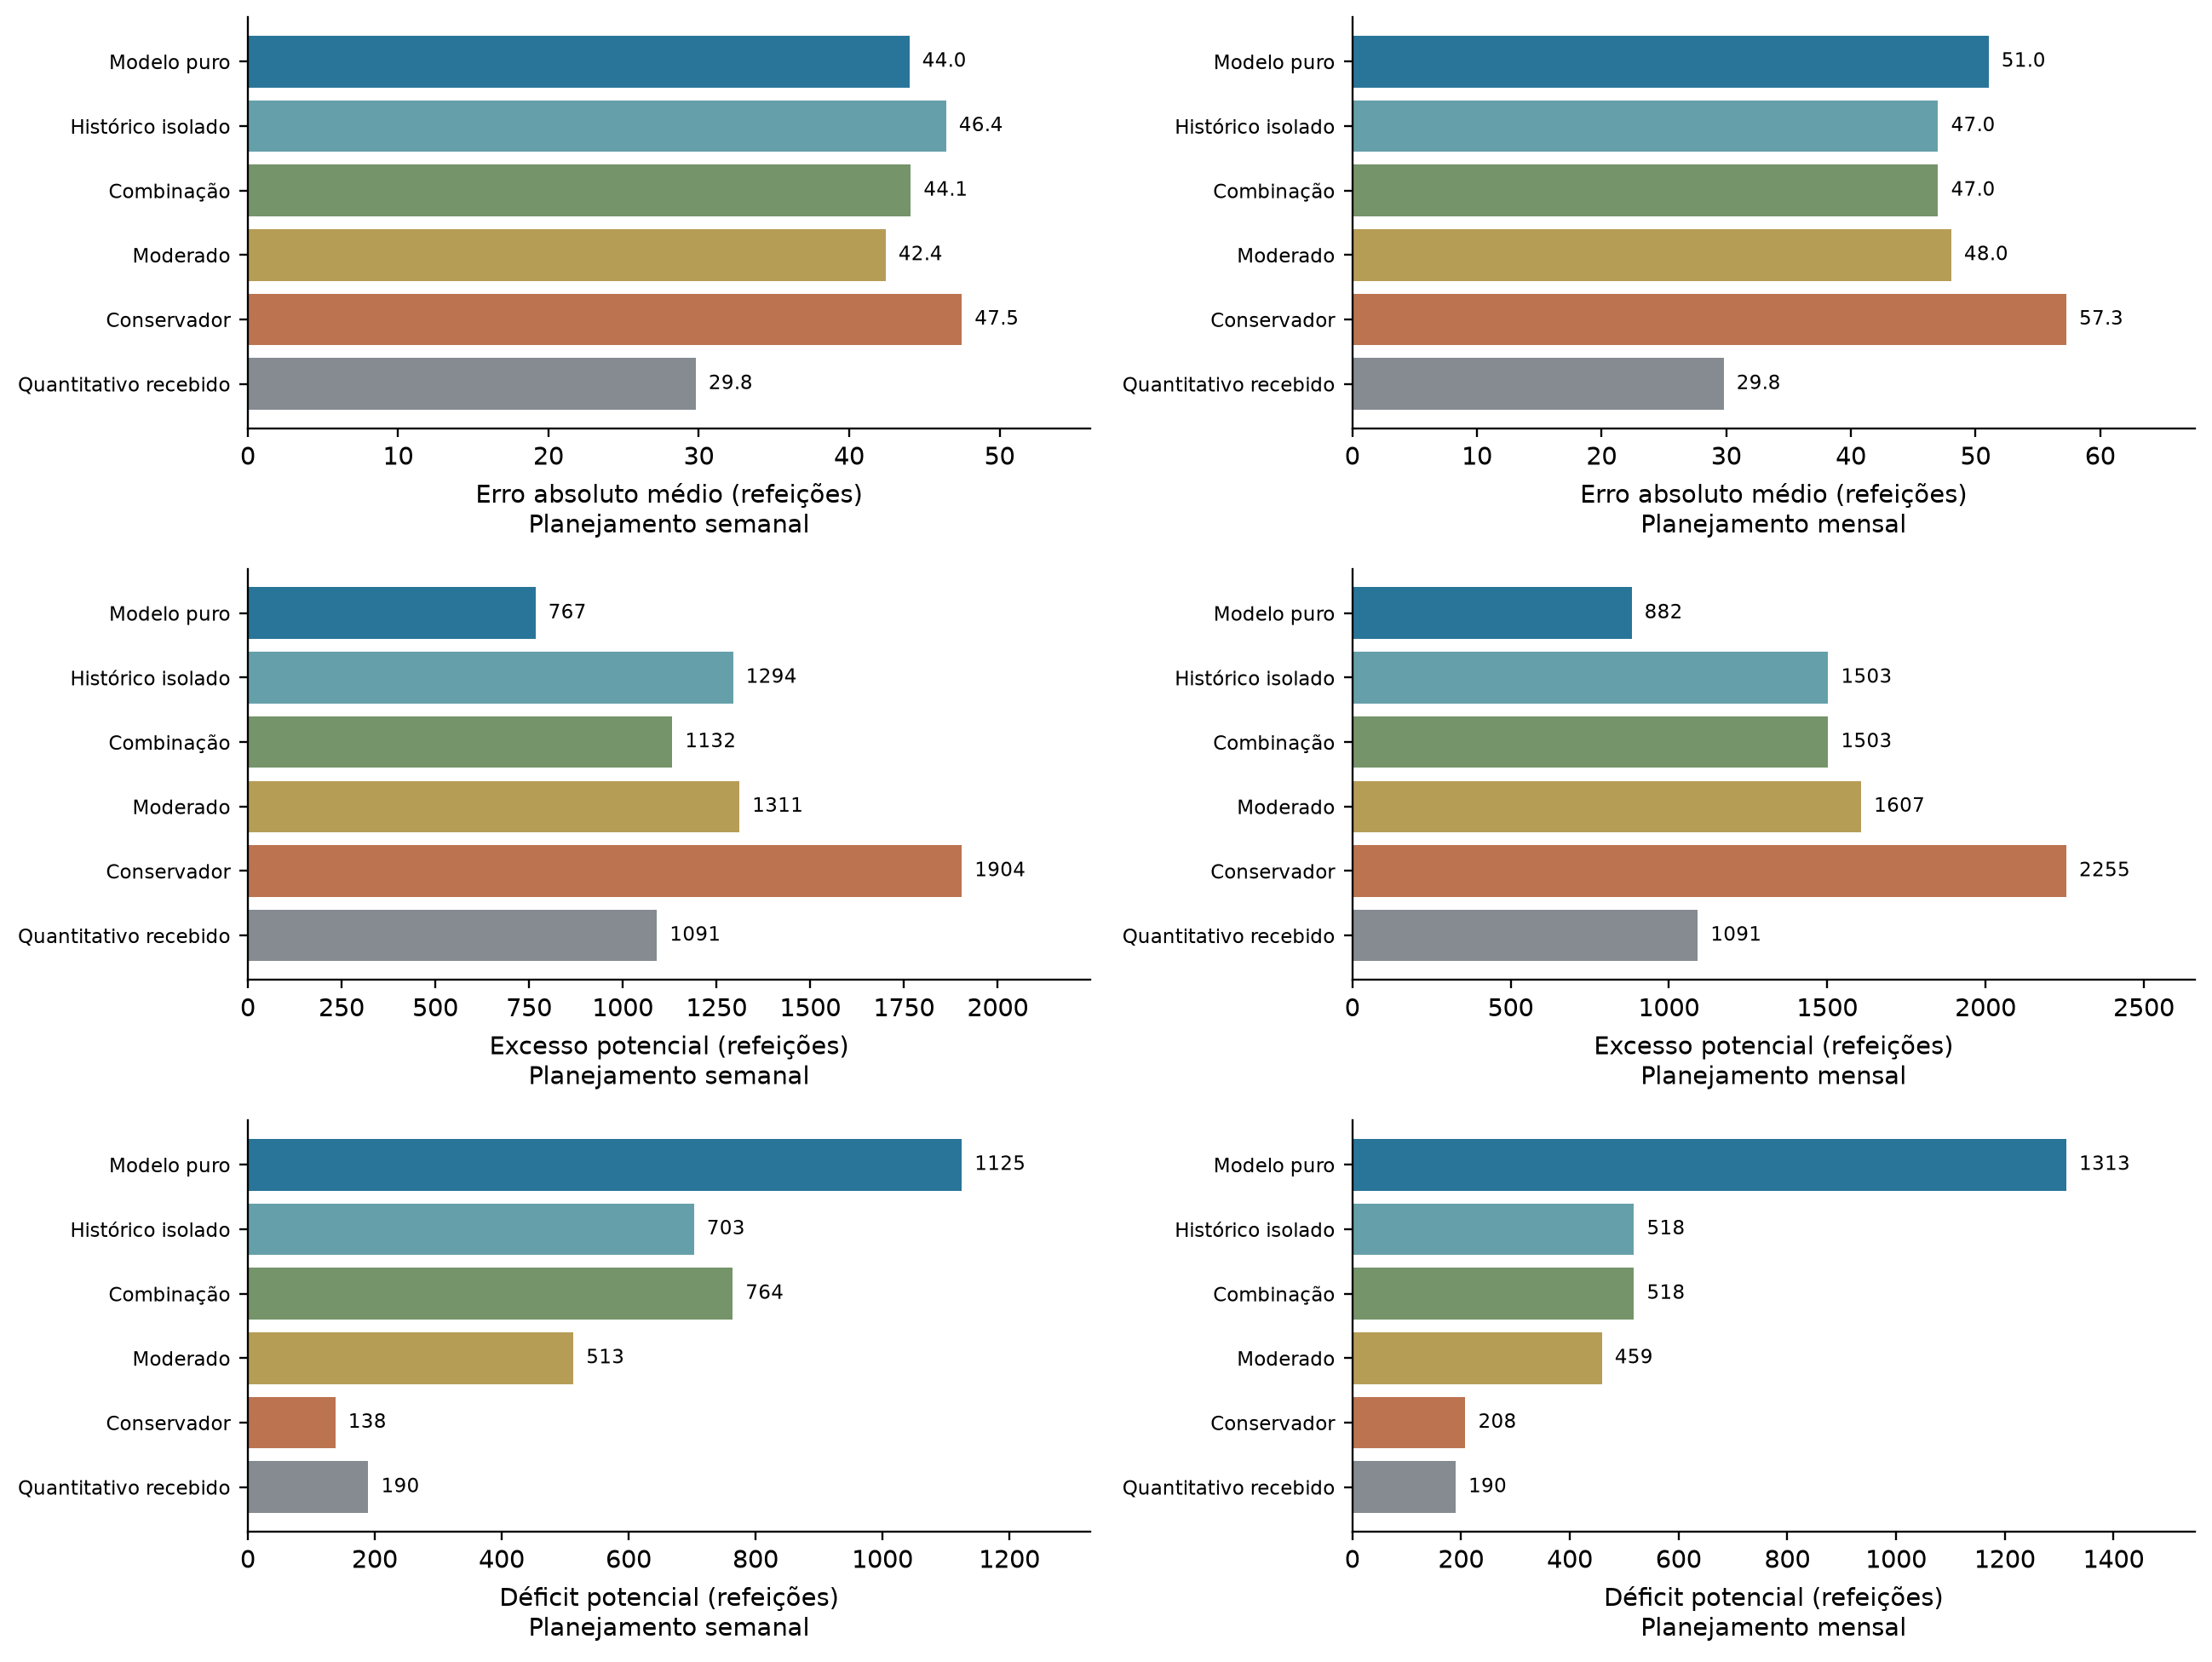

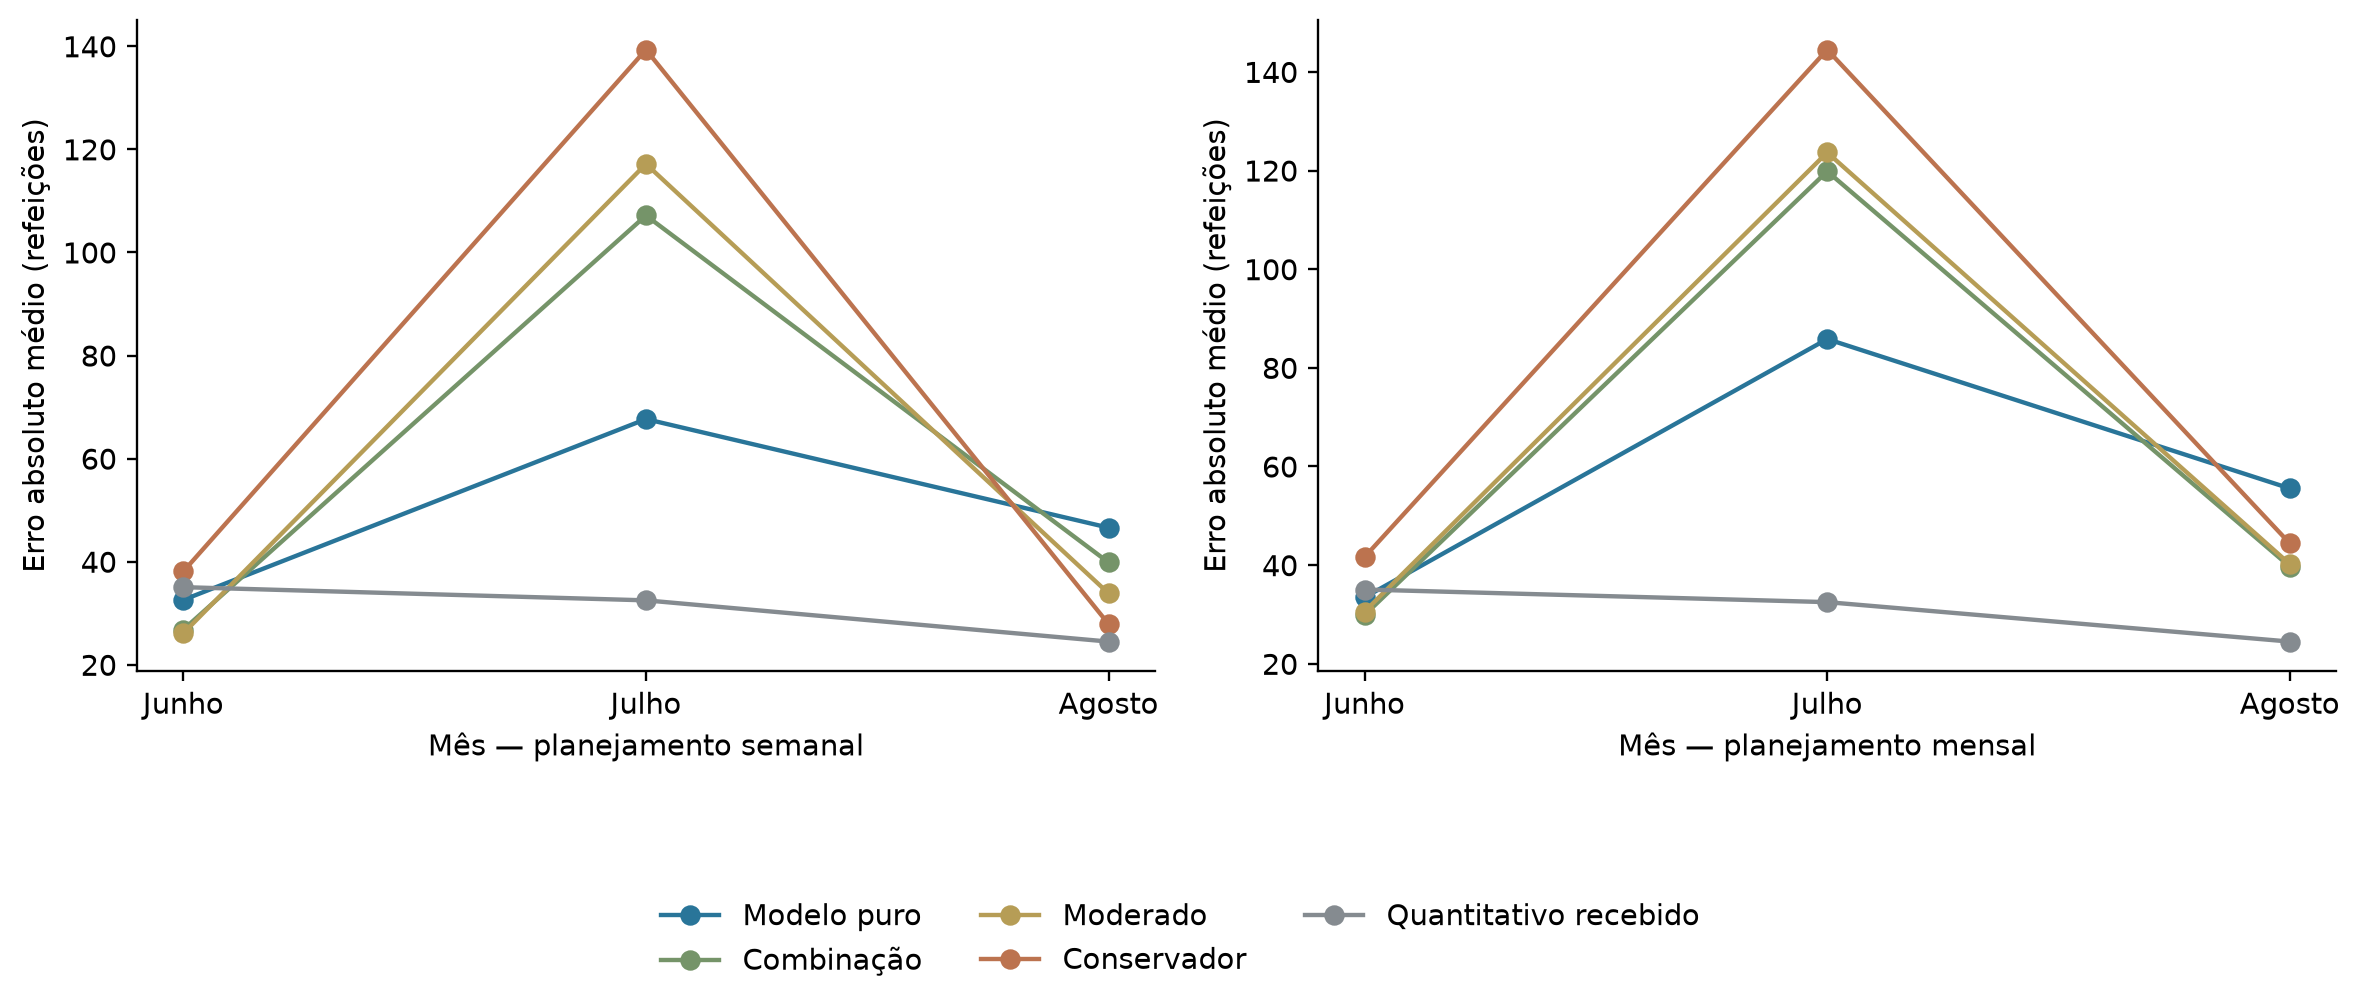

In [3]:
display(Image(filename=str(OUT/"figuras/comparacao_conferencia.png")))
display(Image(filename=str(OUT/"figuras/erro_por_mes.png")))


In [4]:
for name in ["mensal_20261003","semanal_20261005_20261009"]:
    print(name)
    display(pd.read_csv(OUT/"emissoes_outubro"/name/"cenarios_para_gestao.csv",sep=";"))
    display(pd.read_csv(OUT/"emissoes_outubro"/name/"previsoes_congeladas.csv")[["data","estimativa_historico_institucional","n_quantitativos_passados","ultima_data_quantitativo_usado","peso_modelo","peso_historico"]].round(2))
display(json.loads((OUT/"checagens.json").read_text(encoding="utf-8")))
display(json.loads((OUT/"confrontos/status_avaliacao.json").read_text(encoding="utf-8")))


mensal_20261003


,Data,Dia da semana,Modelo puro,Combinação sem margem,Plano moderado,Plano conservador contra falta
0,05/10/2026,segunda-feira,180,232,235,256
1,06/10/2026,terça-feira,170,193,197,218
2,07/10/2026,quarta-feira,172,212,216,237
3,08/10/2026,quinta-feira,166,150,154,175
4,09/10/2026,sexta-feira,172,153,156,177
5,19/10/2026,segunda-feira,181,232,235,256
6,20/10/2026,terça-feira,171,193,197,218
7,21/10/2026,quarta-feira,171,212,216,237
8,22/10/2026,quinta-feira,167,150,154,175
9,23/10/2026,sexta-feira,175,153,156,177


,data,estimativa_historico_institucional,n_quantitativos_passados,ultima_data_quantitativo_usado,peso_modelo,peso_historico
0,2026-10-05,231.11,27,2026-09-28,0.0,1.0
1,2026-10-06,192.85,27,2026-09-29,0.0,1.0
2,2026-10-07,211.69,32,2026-09-30,0.0,1.0
3,2026-10-08,149.81,31,2026-10-01,0.0,1.0
4,2026-10-09,152.07,28,2026-10-02,0.0,1.0
5,2026-10-19,231.11,27,2026-09-28,0.0,1.0
6,2026-10-20,192.85,27,2026-09-29,0.0,1.0
7,2026-10-21,211.69,32,2026-09-30,0.0,1.0
8,2026-10-22,149.81,31,2026-10-01,0.0,1.0
9,2026-10-23,152.07,28,2026-10-02,0.0,1.0


semanal_20261005_20261009


,Data,Dia da semana,Modelo puro,Combinação sem margem,Plano moderado,Plano conservador contra falta
0,05/10/2026,segunda-feira,182,216,226,249
1,06/10/2026,terça-feira,171,203,213,235
2,07/10/2026,quarta-feira,173,211,221,243
3,08/10/2026,quinta-feira,168,192,202,225
4,09/10/2026,sexta-feira,173,186,196,219


,data,estimativa_historico_institucional,n_quantitativos_passados,ultima_data_quantitativo_usado,peso_modelo,peso_historico
0,2026-10-05,227.5,4,2026-09-28,0.25,0.75
1,2026-10-06,212.5,4,2026-09-29,0.25,0.75
2,2026-10-07,222.5,4,2026-09-30,0.25,0.75
3,2026-10-08,200.0,4,2026-10-01,0.25,0.75
4,2026-10-09,190.0,4,2026-09-25,0.25,0.75


{'quantitativos_futuros_na_estatistica': False,
 'invariancia_quantitativo_alvo_e_futuro': True,
 'estimador_ml_retreinado': False,
 'consumos2026_para_comb_margens': 'Somente seleção março–abril, antes01/05',
 'conferencia_alimenta_escolha': False,
 'n_selecao': 36,
 'n_conferencia': 43,
 'previsoes_anteriores_preservadas_sha256': {'resultados/validacao_setembro_2026/previsoes_setembro_2026_congeladas.csv': 'b1eab67d2ff66263f715adf66b4658e0918d52bb030aa8639eca81d11725fd6a',
  'resultados/validacao_prospectiva_20261005/previsoes_congeladas_20261005_20261009.csv': '06a0733d517d39b555253821d581fdad64478f7b8293f789591e7b3118dbb949',
  'resultados/validacao_prospectiva_20261005/emissoes/20261003_candidato_hibrido_v2/previsoes_congeladas.csv': 'fe5146a948631ab3a02c004d208ddd5bd4b15ba42c8cf8fe2bffb25a0744d818',
  'resultados/validacao_outubro_2026/emissoes/mensal_20261003/previsoes_congeladas.csv': 'f617544ddd45f8b9b31429f49f8413e00a1adc67babd3c16424b3f1b80839343',
  'resultados/cenarios_mar

{'avaliado_em': '2026-10-03T13:38:26-03:00',
 'n_consumos_aprovados': 0,
 'n_datas_consumo_nas_emissoes': 0,
 'previsoes_recalculadas': False,
 'reservas_futuras_necessarias_previsao': False,
 'limite': 'A comparação com o quantitativo recebido deve declarar antecedência distinta. Excesso/déficit são diferenças potenciais.',
 'coleta_sha256': '6fda5648c98bb37112bb56ccf67b7ad33aebfe6143275b09500235f839a15fb5'}

## Resultado e limites

O semanal escolheu 25% do modelo e 75% da mediana dos últimos quatro registros do mesmo dia. O mensal escolheu 100% da média por dia; nesse caso o algoritmo não agregou ganho na seleção e a saída é uma previsão estatística, sem contribuição do ML. A estimativa histórica isolada é mostrada para examinar esse ponto.

Em junho, a combinação reduziu erro frente ao modelo; em julho, a proximidade das férias e o retorno vieram acompanhados de erros altos. Isso é associação descritiva, não explicação causal demonstrada. As estatísticas por dia não representam automaticamente calendário, eventos ou mudanças de período. A seleção não superou o quantitativo recebido da nutricionista no conjunto de 43 datas. As margens reduziram déficit, com mais excesso.

As novas emissões de outubro são suplementares e experimentais, mantendo o modelo puro original. Elas usam inclusive quantitativos passados de setembro, cujos consumos ainda não estão disponíveis. A mesma semana tem valores puros distintos na emissão mensal/semanal devido ao corte de 03/10 ou 02/10. As versões anteriores e o e-mail não foram substituídos.

Excesso e déficit são diferenças potenciais, sem comprovação de desperdício físico ou atendimento não realizado. Os cenários precisam ser confirmados nas refeições futuras. O próximo teste deve examinar contexto do calendário na referência histórica e limitar sua influência quando a amostra do contexto for insuficiente, com regra definida antes da nova avaliação.
